`week 3 TA session 1 was taken by prakhar arora sir but it was on contents of week 4(Theory) and week 5 (Practical) `

`and this note book is week 3 TA session 2 which is actually on week 3 contents (Theory) and week 4 (Practical)`

This notebook demonstrates important preprocessing and feature selection techniques used in machine learning.

We will cover:

* Feature Engineering

* FunctionTransformer

* PolynomialFeatures

* KBinsDiscretizer

* LabelEncoder

* MultiLabelBinarizer

* TransformedTargetRegressor

Feature Selection & Dimensionality Reduction

* VarianceThreshold

* SelectKBest

* SelectPercentile

* GenericUnivariateSelect

* RFE

* RFECV

* Sequential Feature Selection

* PCA

Handling Imbalanced Data

* RandomUnderSampler

* RandomOverSampler

* SMOTE

All examples use sklearn datasets and synthetic datasets.

In [ ]:
# Basic imports used throughout notebook
import numpy as np
import pandas as pd

from sklearn.datasets import load_diabetes, load_iris, make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, LabelEncoder, KBinsDiscretizer
from sklearn.preprocessing import MultiLabelBinarizer, FunctionTransformer
from sklearn.compose import TransformedTargetRegressor

from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, chi2, f_classif,
    SelectPercentile, GenericUnivariateSelect,
    RFE, RFECV, SequentialFeatureSelector
)

from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

import warnings
warnings.filterwarnings("ignore")

## FunctionTransformer

### What is FunctionTransformer?

`FunctionTransformer` allows us to apply a custom transformation function to input features.

It is useful when:
- Data is skewed
- We want log/sqrt transformations
- We need domain-specific mathematical preprocessing
- We want to integrate custom transformations inside pipelines

### Mathematical Idea

If a feature is represented as:

\[
X = [x_1, x_2, ..., x_n]
\]

We apply a function:

\[
X' = f(X)
\]

Examples:
- \( f(x) = \log(x) \)
- \( f(x) = \sqrt{x} \)
- \( f(x) = x^2 \)

This is particularly useful when the data distribution is highly skewed.

### Important Notes
- FunctionTransformer does NOT learn parameters.
- It simply applies a deterministic function.
- Can be safely used inside sklearn pipelines.

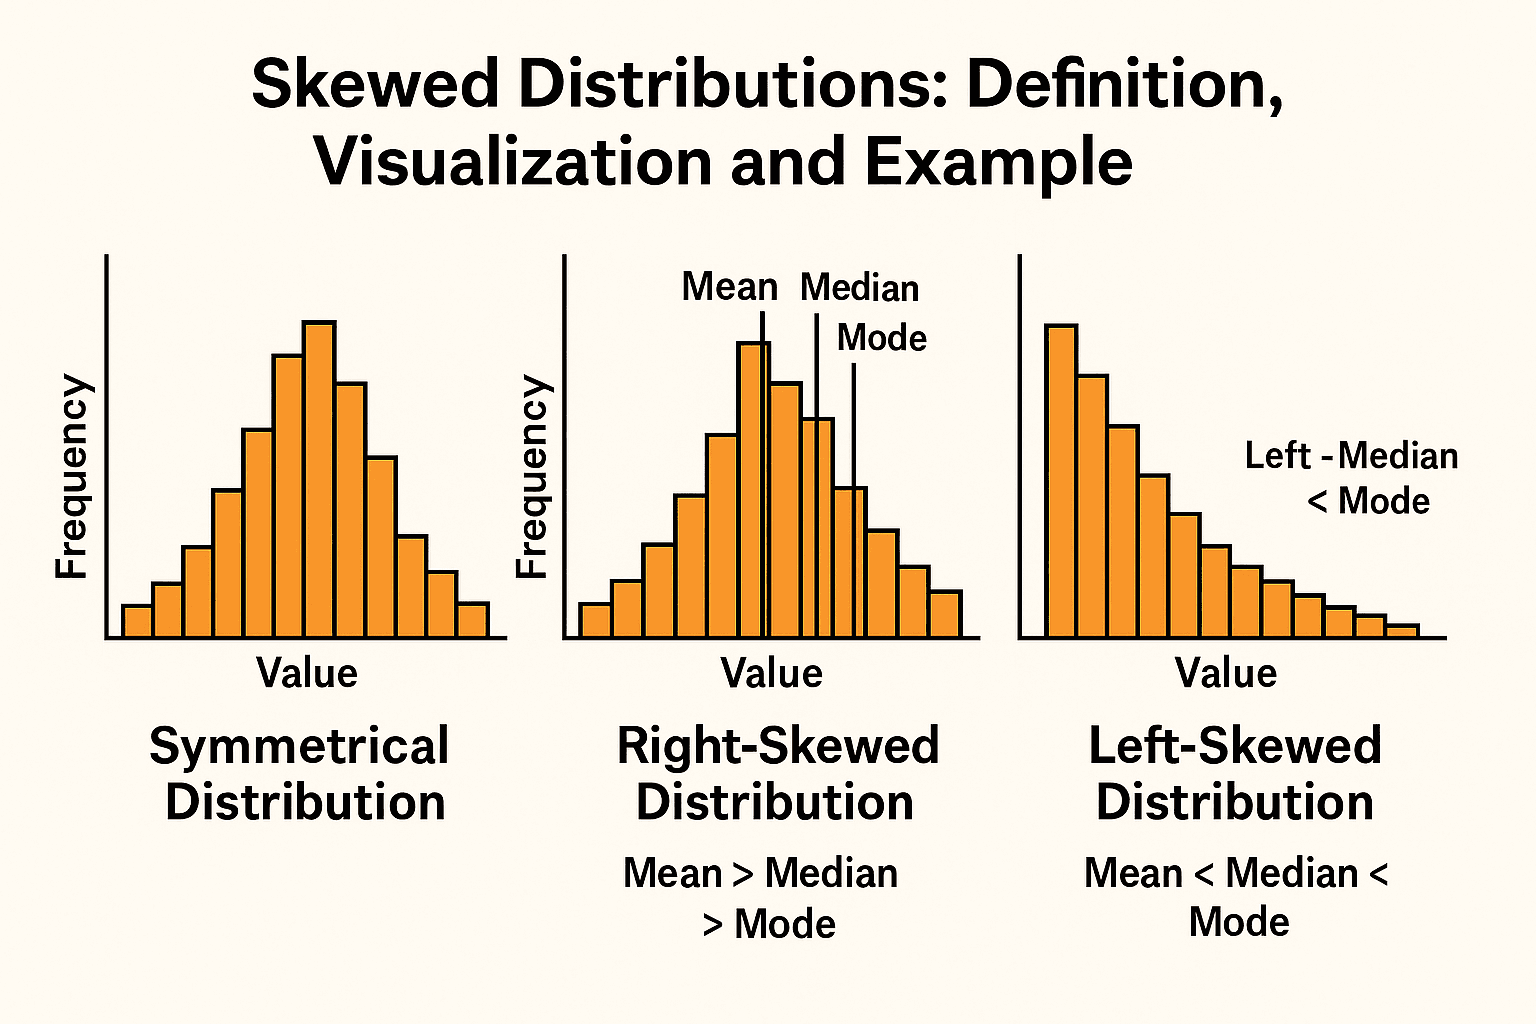

In [ ]:
# create skewed data
X = np.array([[1], [10], [100], [1000]])

print("Original:\n", X)

# apply log transform
log_transform = FunctionTransformer(np.log1p)
X_transformed = log_transform.fit_transform(X)

print("\nLog transformed:\n", X_transformed)

Original:
 [[   1]
 [  10]
 [ 100]
 [1000]]

Log transformed:
 [[0.69314718]
 [2.39789527]
 [4.61512052]
 [6.90875478]]


## Polynomial Features

### What are Polynomial Features?

PolynomialFeatures expand the feature space by adding polynomial combinations of input features.

If input features are:

\[
X = $
[x_1, x_2]
$
\]

Degree = 2 expansion produces:

\[
$
x_1, x_2, x_1^2, x_2^2, x_1x_2
$
\]


### Mathematical Insight

Linear models assume:

\[
y = $
w_1x_1 + w_2x_2 + b
$
\]

After polynomial expansion, the model becomes:

\[
y = $
w_1x_1 + w_2x_2 + w_3x_1^2 + w_4x_2^2 + w_5x_1x_2 + b
$
\]

This allows a linear model to learn **non-linear decision boundaries**.

### Important Notes
- Polynomial features increase dimensionality rapidly.
- High degree -> risk of overfitting.
- Often used with regularization.

In [ ]:
X = np.array([[2, 3]])

poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X)

print("Original:", X)
print("Polynomial features:", X_poly)

Original: [[2 3]]
Polynomial features: [[ 2.  3.  4.  6.  9.  8. 12. 18. 27.]]


### Polynomial Feature Expansion (Degree = 3)

If the input features are:

$
X = [x_1, x_2]
$

A degree 3 polynomial expansion produces the following features.

#### Original Features

$
x_1, x_2
$

#### Degree 2 Terms

$
x_1^2, x_2^2, x_1x_2
$

#### Degree 3 Terms

$
x_1^3, x_2^3, x_1^2x_2, x_1x_2^2
$

### Final Feature Set

$
x_1, x_2, x_1^2, x_2^2, x_1x_2, x_1^3, x_2^3, x_1^2x_2, x_1x_2^2
$

### Total Number of Features

For n input features and polynomial degree d, the total number of generated features excluding the bias term is:

$
\text{Number of features} = \binom{n + d}{d} - 1
$

Where

- n is the number of input features  
- d is the degree of the polynomial  

Substituting

$
n = 2
$

$
d = 3
$

$
\text{Number of features} = \binom{2+3}{3} - 1
$

$
= \binom{5}{3} - 1
$

$
= 10 - 1
$

$
= 9
$

Therefore a degree 3 polynomial expansion of two input features produces 9 features when the bias term is excluded.

## KBins Discretizer

### Purpose

KBinsDiscretizer converts continuous features into discrete bins.

If a continuous feature is:

$$
x \in \mathbb{R}
$$

It is transformed into:

$$
x \rightarrow b_i
$$

where $b_i$ is a bin index.


### Binning Strategies

1. Uniform  
   Equal width bins.

2. Quantile  
   Equal number of samples per bin.

3. KMeans  
   Clustering-based binning.


### When Useful

- Tree-based models
- Rule-based systems
- Reducing impact of outliers


### Important Notes

- Information may be lost if too few bins are used.
- Can simplify complex distributions.

In [ ]:
# Create a simple 2D NumPy array of continuous values
# Note: Scikit-learn expects input data in 2D shape (n_samples, n_features)
X = np.array([[5], [15], [25], [35], [45]])

# Initialize the KBinsDiscretizer object
# n_bins=3, Divide the data into 3 bins
# encode='ordinal', Output bin numbers as integers (0, 1, 2)
# strategy='uniform', Create bins of equal width across the feature range
kb = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',
    strategy='uniform'
)

X_binned = kb.fit_transform(X)

# ravel() converts a 2D array into a flattened 1D array for cleaner printing
print("Original:", X.ravel())

# Print the discretized (binned) output
# Values will be 0, 1, or 2 depending on which bin the number falls into
print("Binned:", X_binned.ravel())


# Since strategy = 'uniform' and values range from 5 to 45:

# Range = 45 − 5 = 40
# Number of bins = 3

# Each bin width = 40 / 3 ≈ 13.33

# So bins roughly become:

# Bin 0 - 5 to ~18.33

# Bin 1 - ~18.33 to ~31.66

# Bin 2 - ~31.66 to 45

Original: [ 5 15 25 35 45]
Binned: [0. 0. 1. 2. 2.]


## LabelEncoder

### Purpose

LabelEncoder converts categorical labels into numeric form.

Example:

Apple -> 0  
Banana -> 1  
Mango -> 2  


### Important Warning

LabelEncoder should be used only for target variables.

Using it for input features can introduce artificial ordering:

Red -> 0  
Green -> 1  
Blue -> 2  

The model may incorrectly assume numerical ordering.

For feature columns, use OneHotEncoder instead.

In [ ]:
le = LabelEncoder()

# Define a list of categorical labels
# These are typically target labels in classification problems
labels = ["apple", "banana", "apple", "mango"]

encoded = le.fit_transform(labels)

print("Original:", labels)

# Print encoded numeric labels
# Each unique category is mapped to an integer
# Example mapping (alphabetical order):
# apple -> 0
# banana -> 1
# mango -> 2
print("Encoded:", encoded)

Original: ['apple', 'banana', 'apple', 'mango']
Encoded: [0 1 0 2]


## MultiLabelBinarizer

### Purpose

Used when a single sample can belong to multiple categories.

Example:

["milk", "bread"]  
["bread", "butter"]

Becomes:

| milk | bread | butter |
|------|-------|--------|
| 1    | 1     | 0      |
| 0    | 1     | 1      |


### Mathematical View

Transforms a set of labels into a binary indicator vector:

$$
\{label_1, label_2\} \rightarrow [1, 1, 0, \dots]
$$


### Applications

- Recommendation systems
- Tag prediction
- Multi-label classification

In [ ]:
mlb = MultiLabelBinarizer()

# Define a dataset where each sample can have multiple labels
# Each inner list represents one sample with multiple categories
data = [
    ["milk", "bread"],      # Sample 1 has two labels
    ["bread", "butter"],    # Sample 2 has two labels
    ["milk"]                # Sample 3 has one label
]

# indicating presence (1) or absence (0) of each label
encoded = mlb.fit_transform(data)

# Print the learned classes in sorted order
# These define the column order of the output matrix
print("Classes:", mlb.classes_)

# Print the binary encoded matrix
# Each row corresponds to one sample
# Each column corresponds to one label
print(encoded)

Classes: ['bread' 'butter' 'milk']
[[1 0 1]
 [1 1 0]
 [0 0 1]]


## LabelEncoder vs MultiLabelBinarizer

LabelEncoder and MultiLabelBinarizer are both preprocessing tools used to convert categorical labels into numerical form, but they are designed for different types of classification problems.

LabelEncoder is used when each data sample belongs to only one class. It converts categorical labels into integer values by assigning a unique number to each class. For example, if the labels are:

["apple", "banana", "apple", "mango"]

LabelEncoder may convert them into:

[0, 1, 0, 2]

Here, each sample has exactly one label, so a single integer representation is sufficient. LabelEncoder is most commonly used for encoding target variables in standard classification problems where one sample corresponds to one class.

In contrast, MultiLabelBinarizer is used when each data sample can belong to multiple classes simultaneously. Instead of assigning a single integer to each sample, it creates a binary matrix where each column represents a class and each row represents a sample. A value of 1 indicates that the class is present in that sample, and 0 indicates absence.

For example, if the dataset is:

["milk", "bread"]  
["bread", "butter"]  
["milk"]

The transformed output becomes:

| bread | butter | milk |
|------|--------|------|
| 1    | 0      | 1    |
| 1    | 1      | 0    |
| 0    | 0      | 1    |

This representation allows a model to understand that a single sample can belong to multiple categories at the same time.

In summary, LabelEncoder is suitable for single-label classification where each sample has only one class, while MultiLabelBinarizer is used for multi-label classification where a sample may belong to multiple classes simultaneously.

## TransformedTargetRegressor

### Purpose

Applies transformation to the target variable before training.

Original problem:

$$
y = f(X)
$$

Transformed problem:

$$
g(y) = f(X)
$$

Prediction is then inverted:

$$
y = g^{-1}(f(X))
$$


### Common Example

Log transformation:

$$
\log(y) = f(X)
$$

Prediction:

$$
y = e^{f(X)}
$$


### Why Useful

- Target variable is skewed
- Reduces heteroscedasticity
- Stabilizes variance

In [ ]:
# This is a regression dataset commonly used for testing regression models
from sklearn.datasets import load_diabetes

# Load feature matrix X and target vector y
# X contains input features
# y contains the target variable (disease progression measure)
X, y = load_diabetes(return_X_y=True)

# Create a TransformedTargetRegressor object
# This wrapper allows us to transform the target variable before training
model = TransformedTargetRegressor(

    # Base regression model to use
    # Here we use Linear Regression
    regressor=LinearRegression(),

    # Function applied to target variable before training
    # np.log1p computes log(1 + y)
    # Useful when target values are skewed
    func=np.log1p,

    # Inverse function to convert predictions back to original scale
    # np.expm1 computes exp(y) - 1
    inverse_func=np.expm1
)

# Fit the model on input features X and transformed target y
# Internally:
# 1. y is transformed using log1p
# 2. Linear regression is trained on transformed y
model.fit(X, y)

# Predict for first 5 samples
# Model predicts in transformed space and then converts back
pred = model.predict(X[:5])

# Print predicted values in original target scale
print("Predictions:", pred)

Predictions: [192.9247086   70.98479332 157.69048298 153.09214761 114.66713347]


In [ ]:
# to do the same thing as above
# Step 1: Transform the target manually
y_transformed = np.log1p(y)

# Step 2: Train regression model on transformed target
model = LinearRegression()
model.fit(X, y_transformed)

# Step 3: Make predictions in transformed space
y_pred_transformed = model.predict(X[:5])

# Step 4: Apply inverse transformation
y_pred = np.expm1(y_pred_transformed)

print("Predictions:", y_pred)

Predictions: [192.9247086   70.98479332 157.69048298 153.09214761 114.66713347]


## Variance Threshold

### Concept

Removes features with very low variance.

Variance of a feature:

$$
Var(X) = \frac{1}{n} \sum_{i=1}^{n} (x_i - \mu)^2
$$

If:

$$
Var(X) \approx 0
$$

The feature carries little information.


### Characteristics

- Unsupervised method
- Does not consider target variable
- Useful as a first preprocessing step

In [ ]:
# Create a small dataset with 3 features (columns) and 3 samples (rows)
# Feature 1: [1, 1, 1]  - constant (no variance)
# Feature 2: [2, 5, 8]  - changing values (has variance)
# Feature 3: [3, 3, 3]  - constant (no variance)
X = [[1, 2, 3],
     [1, 5, 3],
     [1, 8, 3]]

# Initialize VarianceThreshold
# threshold=0.0 means:
# Remove any feature whose variance is exactly zero
# i.e., features that do not change across samples
selector = VarianceThreshold(threshold=0.0)

# fit_transform performs two steps:
# 1. fit() calculates variance of each feature
# 2. transform() removes features with variance <= threshold
X_new = selector.fit_transform(X)

# Convert original X to NumPy array to easily check its shape
# Shape = (number of samples, number of features)
print("Original shape:", np.array(X).shape)

# Only features with non-zero variance will remain
print("After removal:", X_new.shape)

Original shape: (3, 3)
After removal: (3, 1)


## Univariate Feature Selection

These methods evaluate each feature independently with respect to the target.

### SelectKBest

Selects the top k features based on statistical test scores.

### SelectPercentile

Selects top percentage of features.

### GenericUnivariateSelect

Flexible selection mode.


### Common Statistical Tests

- Chi-square test
- ANOVA F-test
- Mutual information

These measure dependency between feature and target.


### Important Notes

- Evaluates features independently.
- Does not capture feature interactions.

### ANOVA F-Statistic (f_classif)

The ANOVA F-statistic is used to measure how strongly each feature is related to the target variable in classification problems.

It compares:
- Variance between class means  
- Variance within each class  

The formula is:

$$
F = \frac{\text{Variance between classes}}{\text{Variance within classes}}
$$

A high F-score means that the feature varies significantly across different classes and is therefore useful for classification.

A low F-score means the feature does not help distinguish between classes.

In SelectKBest with `f_classif`, features with the highest F-scores are selected as the most important.

In [ ]:
# This is a classification dataset with 4 input features and 3 target classes
from sklearn.datasets import load_iris

# Load feature matrix X and target vector y
# X contains measurements of flowers
# y contains class labels (0, 1, 2)
X, y = load_iris(return_X_y=True)

# Import SelectKBest and f_classif
# SelectKBest selects top k most important features
# f_classif is ANOVA F-test used to measure relationship between feature and target
from sklearn.feature_selection import SelectKBest, f_classif

# Create SelectKBest object
# score_func=f_classif -> use ANOVA F-test for scoring features
# k=2 -> select top 2 best features
selector = SelectKBest(score_func=f_classif, k=2)

# fit_transform performs two steps:
# 1. fit() computes statistical score (F-score) of each feature vs target
# 2. transform() keeps only top k scoring features
X_new = selector.fit_transform(X, y)

# Print original shape of dataset
# Iris dataset originally has 4 features
print("Original shape:", X.shape)

print("Selected shape:", X_new.shape)

Original shape: (150, 4)
Selected shape: (150, 2)


In [ ]:
# Create SelectPercentile object
# score_func=f_classif -> use ANOVA F-test to score each feature
# percentile=50 -> keep top 50 percent of features based on score
selector = SelectPercentile(score_func=f_classif, percentile=50)

# fit_transform performs two operations:
# 1. fit() computes F-score of each feature against target variable
# 2. transform() retains only top 50 percent of features
X_new = selector.fit_transform(X, y)

# If original dataset had 4 features, keeping 50 percent means 2 features retained
print(X_new.shape)

(150, 2)


In [ ]:
# Create GenericUnivariateSelect object
# score_func=f_classif uses ANOVA F-test to score each feature
# mode='k_best' means we want to select a fixed number of top features
# param=2 means select the top 2 features based on F-score
selector = GenericUnivariateSelect(
    score_func=f_classif,
    mode='k_best',
    param=2
)

# fit_transform performs two steps:
# 1. fit calculates the statistical score for each feature
# 2. transform retains only the selected features
X_new = selector.fit_transform(X, y)

print(X_new.shape)

(150, 2)


## Recursive Feature Elimination

### RFE

Procedure:

1. Train model
2. Rank features by importance
3. Remove least important feature
4. Repeat

If model weights are:

$$
w = [w_1, w_2, \dots, w_n]
$$

Smallest $|w|$ is removed first.


### RFECV

RFE combined with cross-validation.

Automatically selects optimal number of features.


### Important Notes

- Model-dependent
- Computationally expensive for large datasets

In [ ]:
# Create a Logistic Regression model
# max_iter=1000 ensures the model has enough iterations to converge
model = LogisticRegression(max_iter=1000)

# Initialize RFE with the model
# n_features_to_select=2 means we want to keep only the best 2 features
rfe = RFE(model, n_features_to_select=2)

# fit_transform performs the following steps:
# 1. Train the model using all features
# 2. Rank features based on importance (model coefficients)
# 3. Remove the least important feature
# 4. Repeat until only 2 features remain
X_new = rfe.fit_transform(X, y)

print(X_new.shape)

(150, 2)


In [ ]:
rfe.estimator_.coef_

array([[-2.7476411 , -1.1703017 ],
       [ 0.08364114, -0.90695071],
       [ 2.66399996,  2.07725241]])

In [ ]:
#                 Feature3   Feature4
# Class 0          -2.7476    -1.1703
# Class 1           0.0836    -0.9070
# Class 2           2.6640     2.0773

# The first dimension (3 rows) corresponds to the number of classes.
# The second dimension (2 rows) corresponds to the number of selected features.
# There are no coefficients for Features 1 and 2 because they were removed by RFE before the final model was trained.

In [ ]:
rfe.ranking_

array([3, 2, 1, 1])

In [ ]:
rfe.support_

array([False, False,  True,  True])

In [ ]:
# Create RFECV object
# LogisticRegression(max_iter=1000) is used as the base model
# cv=5 means 5-fold cross-validation will be used to evaluate performance
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000),
    cv=5
)

# Fit RFECV on dataset
# The algorithm performs the following:
# 1. Trains model using all features
# 2. Removes least important feature
# 3. Evaluates model using cross-validation
# 4. Repeats until optimal number of features is found
rfecv.fit(X, y)

# RFECV determines how many features give best cross-validation performance
print("Optimal features:", rfecv.n_features_)

Optimal features: 4


## Sequential Feature Selection

Two approaches:

### Forward Selection

Start with zero features and add the best one at each step.

### Backward Selection

Start with all features and remove the worst one at each step.

### Difference from RFE

RFE removes features based on model-derived importance scores such as coefficients or feature importances. It eliminates the least important features recursively without evaluating every possible subset.

Sequential Feature Selection evaluates model performance after each addition or removal of a feature. It selects features based on how much they improve the model’s validation performance rather than relying only on importance rankings.

As a result, Sequential Feature Selection can capture feature interactions better, while RFE is generally faster and more computationally efficient.

### Important Notes

- Flexible  
- Computationally intensive for high dimensions

In [ ]:
# Create SequentialFeatureSelector object
# LogisticRegression(max_iter=1000) is the estimator used to evaluate subsets
# n_features_to_select=2 means we want to select 2 best features
# direction="forward" means start with zero features and add the best one at each step
sfs = SequentialFeatureSelector(
    LogisticRegression(max_iter=1000),
    n_features_to_select=2,
    direction="forward"
)

# fit_transform performs:
# 1. Start with an empty feature set
# 2. Add one feature at a time
# 3. At each step, choose the feature that improves model performance the most
# 4. Stop when 2 features have been selected
X_new = sfs.fit_transform(X, y)

print(X_new.shape)

(150, 2)


## Principal Component Analysis

### Purpose

Reduce dimensionality while preserving maximum variance.


### Mathematical Steps

1. Compute covariance matrix.
2. Compute eigenvalues and eigenvectors.
3. Project data onto eigenvectors.

Transformation:

$$
X' = W^T X
$$

where $W$ contains eigenvectors.


### Properties

- Unsupervised method
- Removes correlation
- Reduces noise
- Components are not easily interpretable

In [ ]:
from sklearn.decomposition import PCA

# Create PCA object
# n_components=2 means we want to reduce the dataset to 2 principal components
# These components capture the maximum variance present in the original data
pca = PCA(n_components=2)

# fit_transform performs two steps:
# 1. fit() computes principal components from the data
#    This involves computing covariance matrix and its eigenvectors
# 2. transform() projects original data onto selected principal components
X_pca = pca.fit_transform(X)
print("Original:", X.shape)

print("Reduced:", X_pca.shape)

Original: (150, 4)
Reduced: (150, 2)


In [ ]:
!pip install imbalanced-learn

## Handling Imbalanced Data

### Problem

One class dominates the dataset.

Example:

Fraud detection  
99 percent normal  
1 percent fraud  

Models may predict only majority class.


## RandomUnderSampler

Randomly removes samples from majority class.

Pros  
Simple  

Cons  
May discard useful information  


## RandomOverSampler

Duplicates minority samples.

Pros  
No information loss  

Cons  
Risk of overfitting  


## SMOTE

Synthetic Minority Oversampling Technique.

Generates synthetic samples between nearest neighbors.

Formula:

$$
x_{new} = x_i + \lambda (x_{neighbor} - x_i)
$$

where:

$$
0 < \lambda < 1
$$

Pros  
Reduces overfitting compared to simple oversampling  

Important  
Apply only after train-test split.

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

# Create a synthetic classification dataset
# n_samples= 1000 creates 1000 total samples
# weights=[0.9, 0.1] creates class imbalance:
# 90 percent of samples belong to class 0
# 10 percent belong to class 1
X, y = make_classification(
    n_samples=1000,
    weights=[0.9, 0.1],
    random_state=42
)

# Create RandomUnderSampler object
# This will randomly remove samples from the majority class
rus = RandomUnderSampler()

# fit_resample performs:
# 1. fit identifies class distribution
# 2. resample randomly removes samples from majority class
#    until classes become balanced
X_res, y_res = rus.fit_resample(X, y)

# Print class distribution before undersampling
# np.bincount counts occurrences of each class label
print("Before:", np.bincount(y))

# Print class distribution after undersampling
# Majority class is reduced to match minority class
print("After:", np.bincount(y_res))

Before: [897 103]
After: [103 103]


In [ ]:
from imblearn.over_sampling import RandomOverSampler

# Create RandomOverSampler object
# It will balance the dataset by oversampling the minority class
ros = RandomOverSampler()

# fit_resample performs two steps:
# 1. Learns the class distribution in the dataset
# 2. Randomly duplicates samples from the minority class
#    until both classes have equal number of samples
X_res, y_res = ros.fit_resample(X, y)


print("Before:", np.bincount(y))

# Print class distribution after oversampling
# np.bincount counts number of samples in each class
# Both classes should now have equal counts
print(np.bincount(y_res))

Before: [897 103]
[897 897]


In [ ]:
# Import SMOTE from imbalanced-learn
# SMOTE stands for Synthetic Minority Oversampling Technique
# It creates synthetic samples for the minority class instead of duplicating rows
from imblearn.over_sampling import SMOTE

# Create SMOTE object
# This will balance the dataset by generating synthetic minority samples
sm = SMOTE()

# fit_resample performs:
# 1. Learns class distribution
# 2. Identifies minority class samples
# 3. Finds nearest neighbors for each minority sample
# 4. Creates synthetic samples between minority neighbors
#    using interpolation
X_res, y_res = sm.fit_resample(X, y)

print("Before:", np.bincount(y))

# Print class distribution after applying SMOTE
# np.bincount counts number of samples in each class
# After SMOTE, both classes should have equal number of samples
print(np.bincount(y_res))

Before: [897 103]
[897 897]
